<a href="https://colab.research.google.com/github/sabbirpuspo/LearningforMe/blob/main/Skill_Morph_XAI_SHAP_Thyroid_DS3_Skill_Morph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable AI and SHAP
## Differentiated Thyroid Cancer Recurrence

**Md. Samiul Islam**
Instructor, Skill Morph Research Lab

---

**Dataset:** Differentiated Thyroid Cancer Recurrence
Real retrospective cohort of **383 patients** followed for at least 10 years over a 15-year period

**Task:** Binary classification. Predict whether cancer **recurred** (`Recurred`: Yes/No) from 16 clinical and pathological features.

**Learning goals**
1. Train and test basic ML classifiers
2. Understand why clinical models need explanations, not only accuracy
3. Apply **SHAP** (SHapley Additive exPlanations) for feature importance

## 1. Setup

In [1]:
!pip install -q shap xgboost

In [16]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight"})

## 2. Load Data

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
df = pd.read_csv("/content/drive/MyDrive/SkillMorph Datasets/Thyroid_Diff.csv")
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


In [6]:
pd.DataFrame({"dtype": df.dtypes, "missing": df.isna().sum(), "unique": df.nunique()})

,dtype,missing,unique
Age,int64,0,65
Gender,object,0,2
Smoking,object,0,2
Hx Smoking,object,0,2
Hx Radiothreapy,object,0,2
Thyroid Function,object,0,5
Physical Examination,object,0,5
Adenopathy,object,0,6
Pathology,object,0,4
Focality,object,0,2


## 3. Preprocessing

In [7]:
from sklearn.preprocessing import LabelEncoder

df = df.drop_duplicates().reset_index(drop=True)
for col in df.select_dtypes("object"):
    df[col] = LabelEncoder().fit_transform(df[col])

X = df.drop(columns="Recurred")
y = df["Recurred"]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

## 4. Machine Learning Models

### 4.1 Train

In [9]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}

for model in models.values():
    model.fit(X_train, y_train)

### 4.2 Test

In [10]:
results = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

results = pd.DataFrame(results).T.round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8493,0.7895,0.6818,0.7317,0.9349
Decision Tree,0.9315,0.8400,0.9545,0.8936,0.9541
Random Forest,0.9726,0.9545,0.9545,0.9545,0.9603
Gradient Boosting,0.9315,0.8400,0.9545,0.8936,0.9804
XGBoost,0.9589,0.9130,0.9545,0.9333,0.9831
SVM,0.9041,0.8571,0.8182,0.8372,0.9528
KNN,0.8630,0.8750,0.6364,0.7368,0.9162


## 5. SHAP: SHapley Additive exPlanations

High accuracy is not enough in medicine: a clinician must know **why** the model predicts recurrence for a patient.

SHAP comes from cooperative game theory. Each feature is a *player*; the prediction is the *payout*.
The Shapley value $\phi_j$ is feature $j$'s average marginal contribution over all possible feature coalitions.

**Additivity (local accuracy):** every prediction is decomposed exactly as

$$f(x) = \underbrace{E[f(X)]}_{\text{base value}} + \sum_{j=1}^{M} \phi_j$$

- $\phi_j > 0$ pushes the patient **toward recurrence**; $\phi_j < 0$ pushes **away**.


In [11]:
xgb = models["XGBoost"]
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_test)

### 5.1 SHAP Feature Importance

Features are ranked by mean |SHAP| across all test patients: the longer the bar, the more that feature drives the recurrence prediction.

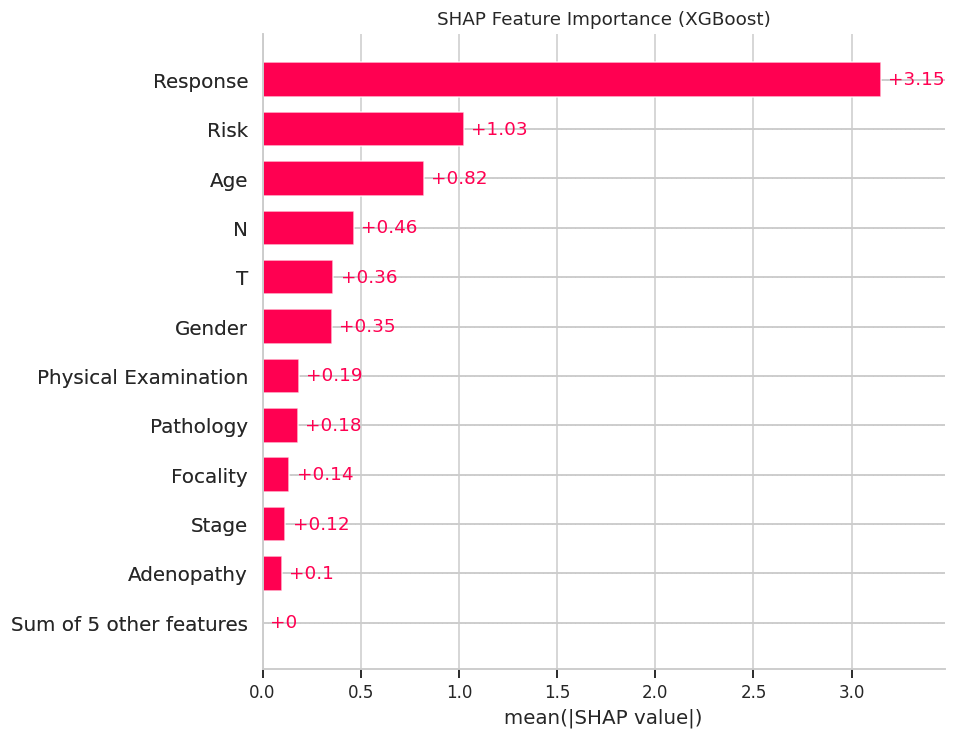

In [15]:
import os

# Ensure the output directory exists
output_dir = "/content/drive/MyDrive/SkillMorph Datasets/figures"
os.makedirs(output_dir, exist_ok=True)

shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("SHAP Feature Importance (XGBoost)")
plt.savefig(os.path.join(output_dir, "shap_feature_importance.png"))
plt.show()

## 6. Key Takeaways

1. **Performance** – Tree ensembles reach very high accuracy, F1 and ROC-AUC on a real clinical cohort.
2. **Why XAI** – high accuracy alone does not tell a clinician *why* a patient is predicted to relapse.
3. **SHAP** – theoretically grounded (Shapley values), and ranks features by their average contribution to the prediction.




*Md. Samiul Islam · Skill Morph Research Lab*